# v3 — locating the 1:2 tongue: f_s sweep, 55 → 90 Hz

Same network as v2, two changes:

1. **Monophasic pulses, no recharge.** With immediate charge balance the stimulus was cancelling
   itself: τ_m = 3.33 ms and the 60 µs pulse + 240 µs recharge lasts 300 µs with zero net charge,
   so the membrane integrated it to ~9% of the leading phase. Sermon et al. use a single
   time-step positive pulse with no recharge throughout, for this reason.
2. **PSDs extended to 200 Hz** so stimulus harmonics (2·f_s) are visible alongside 3f_s/2.

**The question.** Locking at 1:2 means the rhythm sits at *exactly* f_s/2. Pulling means it is
dragged toward f_s/2 without being captured. These look similar in a single PSD and are trivially
separable across a sweep:

- **locked** → observed peak lies *on* the line `f = f_s/2`, and the endogenous ~29 Hz bump is
  gone (entrainment is winner-take-all)
- **pulled** → observed peak deviates from `f_s/2`, and sidebands appear at `f_s ± f_r` from
  intermodulation with a still-free-running rhythm

Panel 3 below plots observed peak against f_s with `f_s/2` overlaid. A flat-to-diagonal
**plateau** on that line is the locking signature — this is Duchet et al.'s §4.2 criterion
(|R − p/q| small *and* the derivative flat), drawn in frequency rather than rotation number.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from brian2 import *
from scipy import signal      # after brian2: `from brian2 import *` shadows `signal`

prefs.devices.cpp_standalone.extra_make_args_unix = ['-j4']
set_device('cpp_standalone', directory='/tmp/hh_v2_build', build_on_run=True)
BrianLogger.suppress_name('resolution_conflict', 'method_choice')

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9,
                     'axes.grid': True, 'grid.alpha': 0.25})

In [2]:
SEED = 2

DT      = 0.02*ms
REC_DT  = 0.5*ms
DISCARD = 1.0*second

NE, NI = 400, 100

CM   = 200*pF
G_NA = 24*uS
G_K  = 7.2*uS
G_L  = 60*nS

E_NA = 50*mV
E_K  = -77*mV
E_L  = -54.4*mV

E_AMPA = 0*mV
E_GABA = -80*mV

TAU_AMPA_RISE  = 0.5*ms
TAU_AMPA_DECAY = 2.0*ms
TAU_GABA_RISE  = 0.5*ms
TAU_GABA_DECAY = 16.0*ms


def gate_jump_norm(tau_rise, tau_decay):
    tr, td = float(tau_rise/ms), float(tau_decay/ms)
    t_peak = tr*td/(td - tr)*np.log(td/tr)
    peak = td/(td - tr)*(np.exp(-t_peak/td) - np.exp(-t_peak/tr))
    return 1.0/peak


AMPA_NORM = gate_jump_norm(TAU_AMPA_RISE, TAU_AMPA_DECAY)
GABA_NORM = gate_jump_norm(TAU_GABA_RISE, TAU_GABA_DECAY)
print(f'AMPA gate normalization = {AMPA_NORM:.3f}')
print(f'GABA gate normalization = {GABA_NORM:.3f}')

g_AMPA_ext_E = 2.08*nS
g_AMPA_ext_I = 1.62*nS
g_AMPA_rec_E = 0.104*nS * 800/NE
g_AMPA_rec_I = 0.081*nS * 800/NE
g_GABA_E     = 1.25*nS * 200/NI
g_GABA_I     = 0.973*nS * 200/NI

w_EE, w_EI, w_IE, w_II = 5.0, 9.0, 5.0, 1.5
P_EE, P_EI, P_IE, P_II = 0.15, 0.15, 0.15, 0.15

N_EXT_E, N_EXT_I = 300, 300
RATE_EXT_E, RATE_EXT_I = 5*Hz, 6*Hz
w_EXT_E, w_EXT_I = 0.625, 0.68

I_TONIC_E = 0.40*nA
I_TONIC_I = 0.40*nA

CHOSEN_E = 200

AMPA gate normalization = 1.587
GABA gate normalization = 1.118


In [3]:
F_STIM      = 55.0        # Hz
PULSE_WIDTH = 60e-6       # s  -> 3 samples at DT = 0.02 ms
RECHARGE    = 4.0         # negative phase: RECHARGE*PULSE_WIDTH at -amp/RECHARGE

I_PER_MA = 5.0            # nA per mA at R_REF
R_REF    = 2000.0         # um
R_E, R_I = 2000.0, 2000.0 # um
GAIN_E, GAIN_I = 0.3, 1.0 # stimulation targets I (Sermon et al. 2023)

In [4]:
def build_dbs_wave(duration_s, f_stim=F_STIM, amp=1.0, pulse_width=PULSE_WIDTH,
                   recharge_dur=None, dt_s=None, schedule=None,
                   jitter=0.0, alternation=0.0, seed_val=0):
    """Pulse train in mA sampled at dt_s.

    recharge_dur : None  -> monophasic, no recharge. This is what Sermon et al.
                            use throughout (single time-step positive pulse, see
                            the insert in their Fig. 2).
                   float -> balancing charge spread over this many seconds.

    Why no recharge matters here: tau_m = CM/G_L = 3.33 ms, while a 60 us pulse
    with immediate 240 us recharge lasts 300 us = 0.09*tau_m and carries zero net
    charge. A point neuron is a low-pass filter with tau_m, so it integrates that
    doublet to ~9% of the leading phase -- about 0.4 mV instead of 4.5 mV per
    pulse. Charge balance is an electrochemical requirement at the electrode;
    real DBS recruits axonal Na channels on the leading phase and the recharge is
    often passive over milliseconds. Use recharge_dur=8e-3 to check robustness.
    """
    dt_s = dt_s if dt_s is not None else float(DT/second)
    n = int(round(duration_s/dt_s))
    w_pos = int(round(pulse_width/dt_s))
    if w_pos < 2:
        raise ValueError(f'DT={dt_s*1e6:.0f} us cannot resolve a {pulse_width*1e6:.0f} us pulse')
    w_neg = int(round(recharge_dur/dt_s)) if recharge_dur else 0

    rng_ = np.random.default_rng(seed_val)
    k = int(duration_s*f_stim*(1 + 6*jitter)) + 16
    periods = (1 + rng_.normal(0, jitter, k))/f_stim if jitter else np.full(k, 1.0/f_stim)
    periods = np.clip(periods, (w_pos + w_neg + 2)*dt_s, None)
    onsets = np.cumsum(periods) - periods[0]
    onsets = onsets[onsets < duration_s - (w_pos + w_neg + 2)*dt_s]

    amps = amp*(schedule(onsets) if schedule is not None else np.ones_like(onsets))
    if alternation:
        amps = amps*(1 + alternation*(-1.0)**np.arange(len(onsets)))

    wave = np.zeros(n, dtype=np.float32)
    for s, a in zip(np.round(onsets/dt_s).astype(int), amps):
        if a:
            wave[s:s + w_pos] += a
            if w_neg:
                wave[s + w_pos:s + w_pos + w_neg] -= a*w_pos/w_neg
    return wave, onsets, amps


def staircase(t, duration_s, a_max=10.0, n_steps=10, baseline_frac=0.1):
    t0 = baseline_frac*duration_s
    step = (duration_s - t0)/n_steps
    idx = np.floor((np.asarray(t) - t0)/step)
    levels = np.linspace(a_max/n_steps, a_max, n_steps)
    return np.where(idx < 0, 0.0, levels[np.clip(idx, 0, n_steps - 1).astype(int)])


_w, _o, _a = build_dbs_wave(2.0, amp=1.0)
print(f'samples per pulse : {int(round(PULSE_WIDTH/float(DT/second)))}   '
      f'(monophasic, no recharge)')
print(f'per-pulse dV into an I cell at 3 mA : '
      f'{3.0*I_PER_MA*GAIN_I*1e-9*PULSE_WIDTH/float(CM/farad)*1e3:.2f} mV')
print(f'tau_m = CM/G_L = {float(CM/farad)/float(G_L/siemens)*1e3:.2f} ms')

samples per pulse : 3   (monophasic, no recharge)
per-pulse dV into an I cell at 3 mA : 4.50 mV
tau_m = CM/G_L = 3.33 ms


In [5]:
_CURRENTS = """
dv/dt = (
      G_NA*m**3*h*(E_NA-v)
    + G_K*n**4*(E_K-v)
    + G_L*(E_L-v)
    + I_AMPA_ext
    + I_AMPA_rec
    + I_GABA_rec
    + I_tonic
    + I_dbs
    )/CM : volt

dm/dt = alpha_m*(1-m) - beta_m*m : 1
dh/dt = alpha_h*(1-h) - beta_h*h : 1
dn/dt = alpha_n*(1-n) - beta_n*n : 1

alpha_m = 1.0/exprel(-(v + 40*mV)/(10*mV))/ms : Hz
beta_m  = 4.0*exp(-(v + 65*mV)/(18*mV))/ms : Hz

alpha_h = 0.07*exp(-(v + 65*mV)/(20*mV))/ms : Hz
beta_h  = 1.0/(1.0 + exp(-(v + 35*mV)/(10*mV)))/ms : Hz

alpha_n = 0.1/exprel(-(v + 55*mV)/(10*mV))/ms : Hz
beta_n  = 0.125*exp(-(v + 65*mV)/(80*mV))/ms : Hz

dx_AMPA_ext/dt = -x_AMPA_ext/TAU_AMPA_RISE : 1
ds_AMPA_ext/dt = -s_AMPA_ext/TAU_AMPA_DECAY + x_AMPA_ext/TAU_AMPA_RISE : 1

dx_AMPA_rec/dt = -x_AMPA_rec/TAU_AMPA_RISE : 1
ds_AMPA_rec/dt = -s_AMPA_rec/TAU_AMPA_DECAY + x_AMPA_rec/TAU_AMPA_RISE : 1

dx_GABA_rec/dt = -x_GABA_rec/TAU_GABA_RISE : 1
ds_GABA_rec/dt = -s_GABA_rec/TAU_GABA_DECAY + x_GABA_rec/TAU_GABA_RISE : 1
"""

eqs_E = _CURRENTS + """
I_AMPA_ext = g_AMPA_ext_E * s_AMPA_ext * (E_AMPA-v) : amp
I_AMPA_rec = g_AMPA_rec_E * s_AMPA_rec * (E_AMPA-v) : amp
I_GABA_rec = g_GABA_E * s_GABA_rec * (E_GABA-v) : amp
I_dbs      = G_DBS * dbs(t) : amp
I_tonic : amp
G_DBS   : amp
"""

eqs_I = _CURRENTS + """
I_AMPA_ext = g_AMPA_ext_I * s_AMPA_ext * (E_AMPA-v) : amp
I_AMPA_rec = g_AMPA_rec_I * s_AMPA_rec * (E_AMPA-v) : amp
I_GABA_rec = g_GABA_I * s_GABA_rec * (E_GABA-v) : amp
I_dbs      = G_DBS * dbs(t) : amp
I_tonic : amp
G_DBS   : amp
"""


def build_network(duration_s, dbs_wave=None, rec_dt=None, rec_stride=8, seed_val=SEED):
    """Assemble the network. dbs_wave is a numpy array in mA at DT, or None."""
    device.reinit()
    device.activate(directory='/tmp/hh_v2_build', build_on_run=True)
    start_scope()
    seed(seed_val)
    rng = np.random.default_rng(seed_val)
    defaultclock.dt = DT
    rec_dt = rec_dt or REC_DT

    if dbs_wave is None:
        dbs_wave = np.zeros(int(round(duration_s/float(DT/second))), dtype=np.float32)
    dbs = TimedArray(dbs_wave, dt=DT)

    common = dict(CM=CM, G_NA=G_NA, G_K=G_K, G_L=G_L, E_NA=E_NA, E_K=E_K, E_L=E_L,
                  E_AMPA=E_AMPA, E_GABA=E_GABA,
                  TAU_AMPA_RISE=TAU_AMPA_RISE, TAU_AMPA_DECAY=TAU_AMPA_DECAY,
                  TAU_GABA_RISE=TAU_GABA_RISE, TAU_GABA_DECAY=TAU_GABA_DECAY, dbs=dbs)
    namespace_E = dict(common, g_AMPA_ext_E=g_AMPA_ext_E,
                       g_AMPA_rec_E=g_AMPA_rec_E, g_GABA_E=g_GABA_E)
    namespace_I = dict(common, g_AMPA_ext_I=g_AMPA_ext_I,
                       g_AMPA_rec_I=g_AMPA_rec_I, g_GABA_I=g_GABA_I)

    E = NeuronGroup(NE, eqs_E, threshold='v > 0*mV', refractory=2*ms,
                    method='rk4', namespace=namespace_E, name='E')
    I = NeuronGroup(NI, eqs_I, threshold='v > 0*mV', refractory=2*ms,
                    method='rk4', namespace=namespace_I, name='I')

    for G in (E, I):
        G.v = -65*mV
        G.m, G.h, G.n = 0.0529, 0.596, 0.318
        G.x_AMPA_ext = 0; G.s_AMPA_ext = 0
        G.x_AMPA_rec = 0; G.s_AMPA_rec = 0
        G.x_GABA_rec = 0; G.s_GABA_rec = 0

    E.I_tonic = np.clip(rng.normal(float(I_TONIC_E/nA), 0.05, NE), 0.05, None)*nA
    I.I_tonic = np.clip(rng.normal(float(I_TONIC_I/nA), 0.04, NI), 0.05, None)*nA

    E.G_DBS = I_PER_MA*nA * GAIN_E * (R_REF/R_E)
    I.G_DBS = I_PER_MA*nA * GAIN_I * (R_REF/R_I)

    S_EE = Synapses(E, E, model='w : 1', on_pre='x_AMPA_rec_post += AMPA_NORM*w',
                    namespace={'AMPA_NORM': AMPA_NORM}, name='S_EE')
    S_EE.connect(condition='i != j', p=P_EE); S_EE.w = w_EE
    S_EE.delay = '1*ms + rand()*2*ms'

    S_EI = Synapses(E, I, model='w : 1', on_pre='x_AMPA_rec_post += AMPA_NORM*w',
                    namespace={'AMPA_NORM': AMPA_NORM}, name='S_EI')
    S_EI.connect(p=P_EI); S_EI.w = w_EI
    S_EI.delay = '1*ms + rand()*2*ms'

    S_IE = Synapses(I, E, model='w : 1', on_pre='x_GABA_rec_post += GABA_NORM*w',
                    namespace={'GABA_NORM': GABA_NORM}, name='S_IE')
    S_IE.connect(p=P_IE); S_IE.w = w_IE
    S_IE.delay = '3*ms + rand()*1*ms'

    S_II = Synapses(I, I, model='w : 1', on_pre='x_GABA_rec_post += GABA_NORM*w',
                    namespace={'GABA_NORM': GABA_NORM}, name='S_II')
    S_II.connect(condition='i != j', p=P_II); S_II.w = w_II
    S_II.delay = '3*ms + rand()*1*ms'

    # PoissonGroup instead of PoissonInput: identical statistics (independent
    # process of rate N_ext*rate_ext per cell), but survives device.reinit()
    PG_E = PoissonGroup(NE, N_EXT_E*RATE_EXT_E, name='PG_E')
    PG_I = PoissonGroup(NI, N_EXT_I*RATE_EXT_I, name='PG_I')
    S_XE = Synapses(PG_E, E, on_pre=f'x_AMPA_ext_post += {AMPA_NORM*w_EXT_E}', name='S_XE')
    S_XI = Synapses(PG_I, I, on_pre=f'x_AMPA_ext_post += {AMPA_NORM*w_EXT_I}', name='S_XI')
    S_XE.connect(j='i'); S_XI.connect(j='i')

    SP_E, SP_I = SpikeMonitor(E, name='SP_E'), SpikeMonitor(I, name='SP_I')
    RATE_E = PopulationRateMonitor(E, name='RATE_E')
    RATE_I = PopulationRateMonitor(I, name='RATE_I')
    M_CELL = StateMonitor(E, ['v', 's_AMPA_ext', 's_AMPA_rec', 's_GABA_rec'],
                          record=[CHOSEN_E], dt=rec_dt, name='M_CELL')
    M_LFP = StateMonitor(E, ['I_AMPA_ext', 'I_AMPA_rec', 'I_GABA_rec'],
                         record=np.arange(0, NE, rec_stride), dt=rec_dt, name='M_LFP')

    net = Network(E, I, S_EE, S_EI, S_IE, S_II, PG_E, PG_I, S_XE, S_XI,
                  SP_E, SP_I, RATE_E, RATE_I, M_CELL, M_LFP)
    net.run(duration_s*second)

    return dict(net=net, E=E, I=I, SP_E=SP_E, SP_I=SP_I,
                RATE_E=RATE_E, RATE_I=RATE_I, M_CELL=M_CELL, M_LFP=M_LFP,
                duration=duration_s, rec_dt=rec_dt,
                fs=1.0/float(rec_dt/second))

In [6]:
def compute_lfp_proxies(sim):
    t = np.asarray(sim['M_LFP'].t/second)
    I_ext  = np.asarray(sim['M_LFP'].I_AMPA_ext/nA)
    I_recE = np.asarray(sim['M_LFP'].I_AMPA_rec/nA)
    I_recI = np.asarray(sim['M_LFP'].I_GABA_rec/nA)

    lfp_ext     = -np.mean(I_ext,  axis=0)
    lfp_exc_rec = -np.mean(I_recE, axis=0)
    lfp_inh_rec = -np.mean(I_recI, axis=0)
    lfp_recurrent = np.abs(lfp_exc_rec) + np.abs(lfp_inh_rec)
    lfp_total = np.abs(lfp_ext) + lfp_recurrent
    return t, lfp_total, lfp_recurrent, lfp_ext, lfp_exc_rec, lfp_inh_rec


def psd_of(x, fs, nperseg_s=4.0):
    x = signal.detrend(np.asarray(x))
    nper = int(min(len(x), nperseg_s*fs))
    return signal.welch(x, fs=fs, nperseg=nper, noverlap=nper//2)


def aperiodic(f, pxx, fit=((4, 12), (40, 70))):
    """Straight-line 1/f fit on peak-free bands. Excludes the >80 Hz shot-noise
    floor, which otherwise flattens the slope and inflates any apparent bump."""
    k = np.zeros_like(f, dtype=bool)
    for lo, hi in fit:
        k |= (f >= lo) & (f <= hi)
    k &= (f > 0) & (pxx > 0)
    slope, offset = np.polyfit(np.log10(f[k]), np.log10(pxx[k]), 1)
    with np.errstate(divide='ignore'):
        resid = np.log10(pxx) - (slope*np.log10(np.maximum(f, 1e-9)) + offset)
    return resid, slope, offset


def ent_index(f, pxx, f0, gap=5.0, width=5.0, search=1.5):
    side = (((f >= f0 - gap - width) & (f <= f0 - gap)) |
            ((f >= f0 + gap) & (f <= f0 + gap + width)))
    if side.sum() < 4:
        return np.nan, np.nan
    base = 10**np.polyval(np.polyfit(f[side], np.log10(pxx[side]), 1), f0)
    k = np.abs(f - f0) <= search
    return pxx[k].max()/base, f[k][np.argmax(pxx[k])]


def peak_bandwidth(f, pxx, f0, search=4.0, floor_db=3.0):
    k = np.abs(f - f0) <= search
    if k.sum() < 3:
        return np.nan
    fk, pk = f[k], pxx[k]
    i = int(np.argmax(pk)); thr = pk[i]/10**(floor_db/10)
    lo, hi = i, i
    while lo > 0 and pk[lo] > thr: lo -= 1
    while hi < len(pk) - 1 and pk[hi] > thr: hi += 1
    return fk[hi] - fk[lo]


def rotation_number(x, fs, onsets, band, t0=0.0):
    sos = signal.butter(4, band, btype='bandpass', fs=fs, output='sos')
    th = np.unwrap(np.angle(signal.hilbert(signal.sosfiltfilt(sos, np.asarray(x)))))
    t = np.arange(len(x))/fs
    pt = onsets[(onsets > max(t0, t[0])) & (onsets < t[-1])]
    if len(pt) < 50:
        return np.nan
    ph = np.interp(pt, t, th)
    return (ph[-1] - ph[0])/(2*np.pi*(len(ph) - 1))


def isi_cv(mon, min_spikes=5):
    cvs = []
    for tr in mon.spike_trains().values():
        if len(tr) > min_spikes:
            d = np.diff(np.asarray(tr/second))
            if d.mean() > 0:
                cvs.append(d.std()/d.mean())
    return float(np.mean(cvs)) if cvs else np.nan


def summarise(sim, label='', band=(25, 45)):
    d = sim['duration']
    rE = len(sim['SP_E'].i)/(NE*d)
    rI = len(sim['SP_I'].i)/(NI*d)
    t, _, lfp_rec, _, _, _ = compute_lfp_proxies(sim)
    keep = t >= float(DISCARD/second)
    f, pxx = psd_of(lfp_rec[keep], sim['fs'])
    resid, slope, _ = aperiodic(f, pxx)
    b = (f >= 13) & (f <= 45)
    print(f'{label:22s} E {rE:5.2f} Hz (CV {isi_cv(sim["SP_E"]):.2f}) | '
          f'I {rI:5.2f} Hz (CV {isi_cv(sim["SP_I"]):.2f}) | '
          f'bump {f[b][np.argmax(resid[b])]:5.1f} Hz x{10**resid[b].max():4.1f} | '
          f'slope {slope:5.2f}')
    return f, pxx, resid, lfp_rec[keep], t[keep]


def report_dbs(x, fs, onsets, f_stim, band=(25, 45)):
    f, pxx = psd_of(x, fs)
    print(f'  {"target":>8} {"Hz":>7} {"index":>7} {"peak Hz":>8} {"BW Hz":>7}')
    for lab, f0 in [('f_s/2', f_stim/2), ('f_s', f_stim), ('3f_s/2', 1.5*f_stim)]:
        idx, fpk = ent_index(f, pxx, f0)
        print(f'  {lab:>8} {f0:7.1f} {idx:7.2f} {fpk:8.2f} '
              f'{peak_bandwidth(f, pxx, f0):7.2f}')
    R = rotation_number(x, fs, onsets, band)
    print(f'  rotation number ({band[0]}-{band[1]} Hz band): R = {R:.3f}'
          f'   [0.5 = 1:2, 1.0 = 1:1, 1.5 = 3:2]')
    return f, pxx

## Sweep

8 stimulation frequencies at fixed 3 mA, 18 s each, plus an unstimulated baseline. 55 Hz is
included because it is the clinical value, even though it sits below the requested range.

In [7]:
SWEEP_F = [55., 60., 65., 70., 75., 80., 85., 90.]
SWEEP_AMP = 3.0
SWEEP_DUR = 18.0
FMAX = 200.0

def endogenous_peak(f, resid, band=(18, 60), exclude=(), halfwidth=1.5):
    """Strongest aperiodic-corrected peak in `band`, ignoring bins within
    `halfwidth` of any frequency in `exclude` (the stimulus lines)."""
    k = (f >= band[0]) & (f <= band[1])
    for fx in exclude:
        k &= np.abs(f - fx) > halfwidth
    if not k.any():
        return np.nan, np.nan
    i = int(np.argmax(resid[k]))
    return float(f[k][i]), float(10**resid[k][i])


rest = build_network(SWEEP_DUR)
t0, _, lfp0, _, _, _ = compute_lfp_proxies(rest)
keep0 = t0 >= float(DISCARD/second)
f0, p0 = psd_of(lfp0[keep0], rest['fs'])
res0, slope0, _ = aperiodic(f0, p0)
F_REST, PROM_REST = endogenous_peak(f0, res0)
rate0_E = len(rest['SP_E'].i)/(NE*SWEEP_DUR)
print(f'rest: endogenous peak {F_REST:.2f} Hz  x{PROM_REST:.2f}  '
      f'slope {slope0:.2f}  E {rate0_E:.2f} Hz')
del rest

rows, spectra = [], {}
for fs_ in SWEEP_F:
    wave, ons, amps = build_dbs_wave(SWEEP_DUR, f_stim=fs_, amp=SWEEP_AMP)
    sim = build_network(SWEEP_DUR, dbs_wave=wave)
    t, _, lfp, _, _, _ = compute_lfp_proxies(sim)
    keep = t >= float(DISCARD/second)
    x = lfp[keep]
    f, pxx = psd_of(x, sim['fs'])
    resid, slope, _ = aperiodic(f, pxx)

    i_half, f_half = ent_index(f, pxx, fs_/2)
    i_fund, _      = ent_index(f, pxx, fs_)
    i_sesq, f_sesq = ent_index(f, pxx, 1.5*fs_)
    f_obs, prom_obs = endogenous_peak(f, resid, exclude=(fs_, fs_/2, 1.5*fs_, 2*fs_))
    rE = len(sim['SP_E'].i)/(NE*SWEEP_DUR)
    rI = len(sim['SP_I'].i)/(NI*SWEEP_DUR)
    R  = rotation_number(x, sim['fs'], ons, (18., 60.))

    rows.append(dict(f_stim=fs_, i_half=i_half, f_half=f_half, i_fund=i_fund,
                     i_sesq=i_sesq, f_sesq=f_sesq, f_obs=f_obs, prom_obs=prom_obs,
                     bw_half=peak_bandwidth(f, pxx, fs_/2), rate_E=rE, rate_I=rI,
                     slope=slope, R=R))
    spectra[fs_] = (f, pxx, resid)
    print(f'f_s={fs_:5.1f} | idx f_s/2 {i_half:6.2f} at {f_half:6.2f} Hz '
          f'(target {fs_/2:5.2f}) | idx f_s {i_fund:7.2f} | idx 3f_s/2 {i_sesq:6.2f} | '
          f'free peak {f_obs:5.1f} Hz x{prom_obs:4.2f} | E {rE:4.2f} I {rI:4.2f} | R {R:.3f}')
    del sim

rest: endogenous peak 28.75 Hz  x3.39  slope -1.18  E 2.81 Hz


f_s= 55.0 | idx f_s/2   2.09 at  28.75 Hz (target 27.50) | idx f_s 10860.01 | idx 3f_s/2   2.64 | free peak  32.2 Hz x2.72 | E 0.23 I 25.95 | R 1.000


f_s= 60.0 | idx f_s/2   2.09 at  29.25 Hz (target 30.00) | idx f_s 9084.95 | idx 3f_s/2   1.85 | free peak  22.5 Hz x6.41 | E 0.23 I 23.47 | R 0.963


f_s= 65.0 | idx f_s/2   2.35 at  31.25 Hz (target 32.50) | idx f_s 8644.67 | idx 3f_s/2   2.57 | free peak  20.0 Hz x7.42 | E 0.24 I 21.18 | R 0.680


f_s= 70.0 | idx f_s/2   2.55 at  33.75 Hz (target 35.00) | idx f_s 7865.70 | idx 3f_s/2   1.97 | free peak  30.5 Hz x8.44 | E 0.23 I 20.00 | R 0.481


f_s= 75.0 | idx f_s/2   2.31 at  36.25 Hz (target 37.50) | idx f_s 9215.91 | idx 3f_s/2   2.20 | free peak  34.2 Hz x11.33 | E 0.22 I 19.22 | R 0.424


f_s= 80.0 | idx f_s/2   2.34 at  38.75 Hz (target 40.00) | idx f_s 6758.68 | idx 3f_s/2   2.46 | free peak  33.8 Hz x13.47 | E 0.21 I 18.57 | R 0.419


f_s= 85.0 | idx f_s/2   3.43 at  41.75 Hz (target 42.50) | idx f_s 6546.28 | idx 3f_s/2   3.35 | free peak  39.8 Hz x11.17 | E 0.23 I 18.23 | R 0.426


f_s= 90.0 | idx f_s/2  24.81 at  44.00 Hz (target 45.00) | idx f_s 5678.17 | idx 3f_s/2  17.36 | free peak  43.0 Hz x11.17 | E 0.25 I 18.60 | R 0.452


## Panel 1 — spectra to 200 Hz

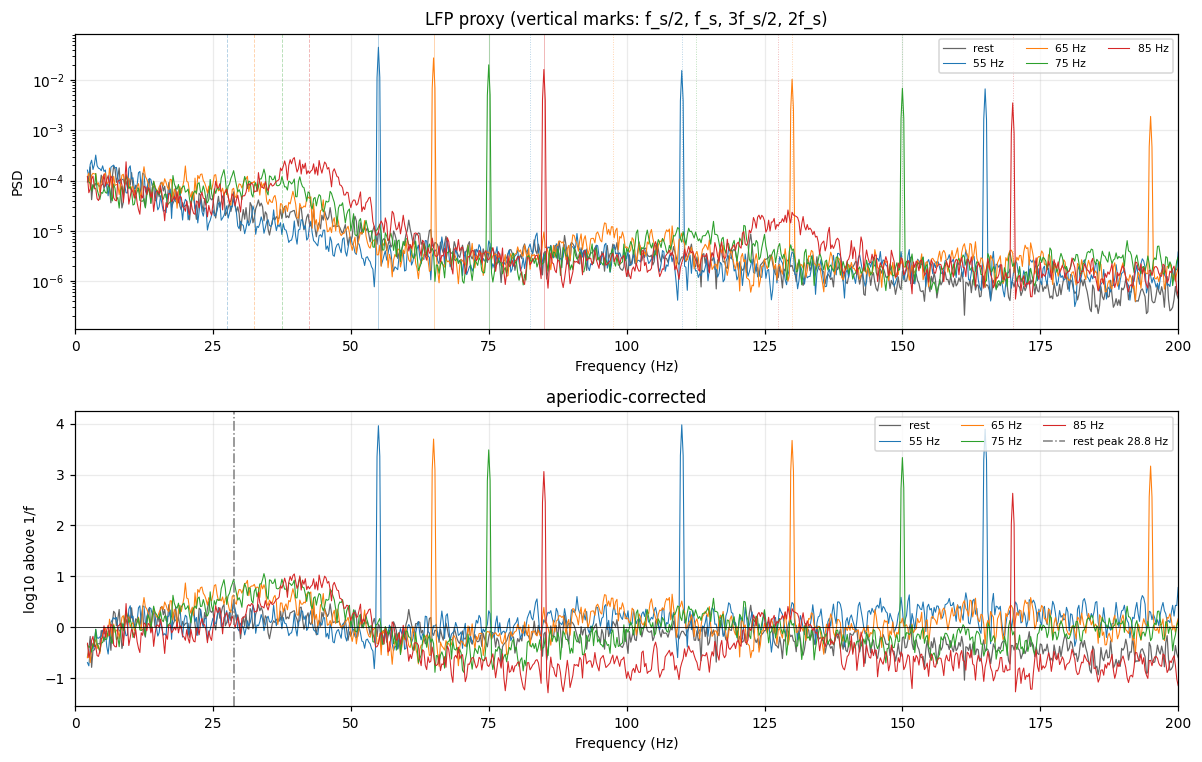

In [8]:
show = [55., 65., 75., 85.]
fig, ax = plt.subplots(2, 1, figsize=(11, 7))
k0 = (f0 > 2) & (f0 <= FMAX)
ax[0].semilogy(f0[k0], p0[k0], 'k-', lw=0.8, alpha=0.6, label='rest')
ax[1].plot(f0[k0], res0[k0], 'k-', lw=0.8, alpha=0.6, label='rest')
for fs_ in show:
    f, pxx, resid = spectra[fs_]
    k = (f > 2) & (f <= FMAX)
    l, = ax[0].semilogy(f[k], pxx[k], lw=0.7, label=f'{fs_:.0f} Hz')
    ax[1].plot(f[k], resid[k], lw=0.7, color=l.get_color(), label=f'{fs_:.0f} Hz')
    for mult, ls in [(0.5, '--'), (1.0, '-'), (1.5, ':'), (2.0, ':')]:
        if mult*fs_ <= FMAX:
            ax[0].axvline(mult*fs_, color=l.get_color(), ls=ls, lw=0.6, alpha=0.35)
ax[1].axhline(0, c='k', lw=0.5)
ax[1].axvline(F_REST, color='C7', ls='-.', lw=1, label=f'rest peak {F_REST:.1f} Hz')
ax[0].set(xlabel='Frequency (Hz)', ylabel='PSD', xlim=(0, FMAX),
          title='LFP proxy (vertical marks: f_s/2, f_s, 3f_s/2, 2f_s)')
ax[1].set(xlabel='Frequency (Hz)', ylabel='log10 above 1/f', xlim=(0, FMAX),
          title='aperiodic-corrected')
ax[0].legend(fontsize=7, ncol=3); ax[1].legend(fontsize=7, ncol=3)
plt.tight_layout(); plt.show()

## Panel 2 — the tongue: entrainment index at f_s/2

Sermon et al.'s threshold of 3 is marked. A tongue shows a clear maximum at the stem; a flat line
means no 1:2 locking anywhere in this range.

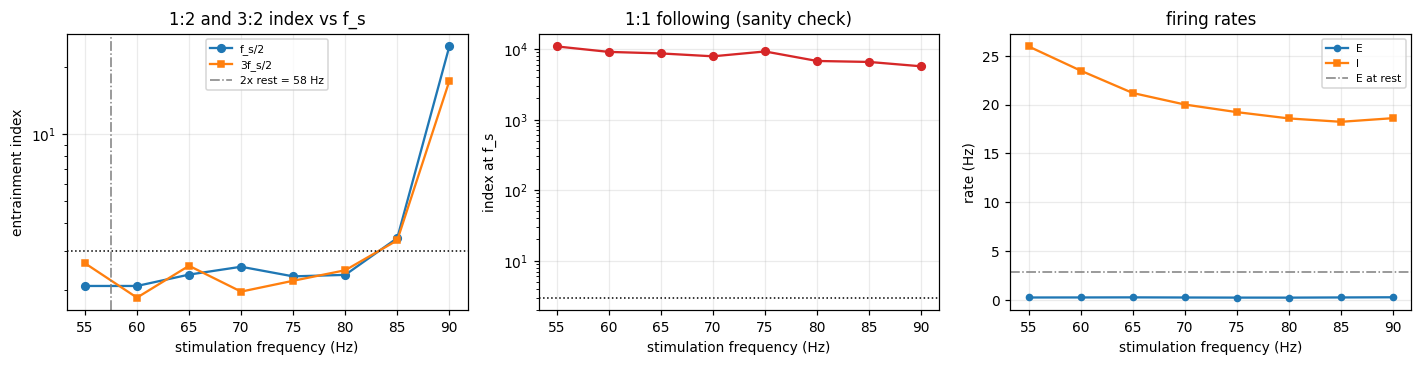

In [9]:
fsv = np.array([r['f_stim'] for r in rows])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(fsv, [r['i_half'] for r in rows], 'o-', ms=5, label='f_s/2')
ax[0].plot(fsv, [r['i_sesq'] for r in rows], 's-', ms=4, label='3f_s/2')
ax[0].axhline(3, c='k', ls=':', lw=1)
ax[0].axvline(2*F_REST, c='C7', ls='-.', lw=1, label=f'2x rest = {2*F_REST:.0f} Hz')
ax[0].set(xlabel='stimulation frequency (Hz)', ylabel='entrainment index',
          yscale='log', title='1:2 and 3:2 index vs f_s')
ax[0].legend(fontsize=7)

ax[1].semilogy(fsv, [r['i_fund'] for r in rows], 'o-', ms=5, color='C3')
ax[1].axhline(3, c='k', ls=':', lw=1)
ax[1].set(xlabel='stimulation frequency (Hz)', ylabel='index at f_s',
          title='1:1 following (sanity check)')

ax[2].plot(fsv, [r['rate_E'] for r in rows], 'o-', ms=4, label='E')
ax[2].plot(fsv, [r['rate_I'] for r in rows], 's-', ms=4, label='I')
ax[2].axhline(rate0_E, c='C7', ls='-.', lw=1, label='E at rest')
ax[2].set(xlabel='stimulation frequency (Hz)', ylabel='rate (Hz)',
          title='firing rates')
ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Panel 3 — locked or pulled

The decisive plot. Grey line is `f = f_s/2`. Orange squares are the strongest aperiodic-corrected
peak *excluding* the stimulus lines.

- peaks sitting **on** the grey line over a range of f_s → 1:2 locking (a plateau)
- peaks **off** the line, drifting slowly with f_s → the rhythm is being pulled, not captured
- peaks pinned near the resting frequency regardless of f_s → the stimulus is not engaging it

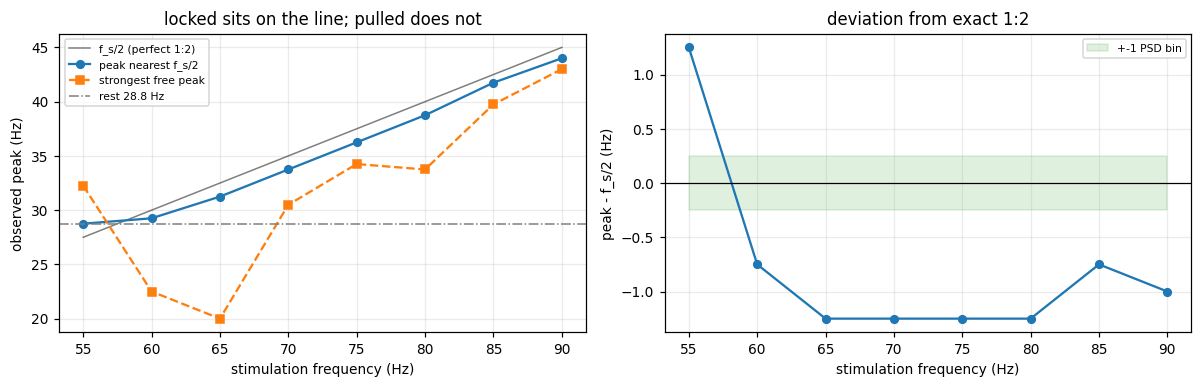

   f_s   f_s/2    peak     dev     idx     BW  free pk      R
  55.0   27.50   28.75    1.25    2.09   1.75     32.2  1.000
  60.0   30.00   29.25   -0.75    2.09   1.00     22.5  0.963
  65.0   32.50   31.25   -1.25    2.35   2.25     20.0  0.680
  70.0   35.00   33.75   -1.25    2.55   3.50     30.5  0.481
  75.0   37.50   36.25   -1.25    2.31   1.25     34.2  0.424
  80.0   40.00   38.75   -1.25    2.34   1.25     33.8  0.419
  85.0   42.50   41.75   -0.75    3.43   2.50     39.8  0.426
  90.0   45.00   44.00   -1.00   24.81   1.00     43.0  0.452


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(fsv, fsv/2, 'k-', lw=1, alpha=0.5, label='f_s/2 (perfect 1:2)')
ax[0].plot(fsv, [r['f_half'] for r in rows], 'o-', ms=5,
           label='peak nearest f_s/2')
ax[0].plot(fsv, [r['f_obs'] for r in rows], 's--', ms=5, color='C1',
           label='strongest free peak')
ax[0].axhline(F_REST, c='C7', ls='-.', lw=1, label=f'rest {F_REST:.1f} Hz')
ax[0].set(xlabel='stimulation frequency (Hz)', ylabel='observed peak (Hz)',
          title='locked sits on the line; pulled does not')
ax[0].legend(fontsize=7)

dev = np.array([r['f_half'] for r in rows]) - fsv/2
ax[1].plot(fsv, dev, 'o-', ms=5)
ax[1].axhline(0, c='k', lw=0.8)
ax[1].fill_between(fsv, -0.25, 0.25, color='C2', alpha=0.15,
                   label='+-1 PSD bin')
ax[1].set(xlabel='stimulation frequency (Hz)', ylabel='peak - f_s/2 (Hz)',
          title='deviation from exact 1:2')
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f'{"f_s":>6} {"f_s/2":>7} {"peak":>7} {"dev":>7} {"idx":>7} {"BW":>6} '
      f'{"free pk":>8} {"R":>6}')
for r in rows:
    print(f'{r["f_stim"]:6.1f} {r["f_stim"]/2:7.2f} {r["f_half"]:7.2f} '
          f'{r["f_half"]-r["f_stim"]/2:7.2f} {r["i_half"]:7.2f} '
          f'{r["bw_half"]:6.2f} {r["f_obs"]:8.1f} {r["R"]:6.3f}')

## Reading it

If panel 2 has a maximum near `2 × f_rest`, that is the stem of the 1:2 tongue, and the horizontal
distance from there down to 55 Hz is what decides whether the patient's 27.5 Hz line is reachable
by this mechanism. Sermon et al. found the 1:2 tongue leans **left** — reachable well below twice
the natural frequency, not above — so 55 Hz sits on the favourable side of a stem near 58 Hz.

If panel 2 is flat and panel 3 shows peaks off the `f_s/2` line everywhere, this network does not
support 1:2 locking at 3 mA. Next steps then, in order: raise amplitude (the tongue widens with
amplitude, so run the charting sweep before concluding), then check whether the sidebands sit at
`f_s ± f_r`, which would identify the features as intermodulation products of a free-running
rhythm rather than entrainment.